# QC Overview

In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

import scatlastb_utils as atl

/hpc/scratch/project.hca_integration/miniforge3/envs/scanpy/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
data_dir = 'data/pipeline/HLCAv1/QC/'

In [3]:
ll {data_dir}/qc/

total 53
drwxr-xr-x   4 michaela.mueller  4096 May 23 06:29 autoqc/
drwxr-xr-x   4 michaela.mueller  4096 Mar 29 16:09 autoqc_old/
drwxr-xr-x 112 michaela.mueller 32768 May 23 10:35 dataset~QC/
drwxr-xr-x  54 michaela.mueller 12288 May 23 10:36 dataset~QC_extended/
-rw-r--r--   1 michaela.mueller 16124 May 23 13:33 input_files.tsv
-rw-r--r--   1 michaela.mueller 24170 May 23 13:33 output_files.tsv


## Read data

In [4]:
obs = atl.io.read_anndata(f'{data_dir}/merge/dataset~QC.zarr', obs='obs')

dask: False, backed: False
Read slot "obs", store as "obs"...
shape: (584944, 0)


In [5]:
thresholds = pd.read_table('data/images/HLCAv1/QC/qc/dataset~QC/thresholds.tsv')

In [6]:
thresholds

,dataset,file_id,threshold_type,passed_frac,removed_frac,n_passed,n_removed,n_total,scrublet_score_min,scrublet_score_max,percent_mito_min,percent_mito_max,n_genes_min,n_genes_max,n_counts_min,n_counts_max
0,QC,split_data:doublets:Banovich_Kropski_2020--spl...,sctk_autoqc,0.861323,0.138677,54601,8791,63392,0.000000,0.116743,0.000000,12.436554,512.916077,6815.001465,893.623413,59216.007812
1,QC,split_data:doublets:Banovich_Kropski_2020--spl...,user,0.000000,1.000000,0,63392,63392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,QC,split_data:doublets:Banovich_Kropski_2020--spl...,alternative,0.000000,1.000000,0,63392,63392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,QC,split_data:doublets:Banovich_Kropski_2020--spl...,updated,0.861323,0.138677,54601,8791,63392,0.000000,0.116743,0.000000,12.436554,512.916077,6815.001465,893.623413,59216.007812
4,QC,split_data:doublets:Barbry_Leroy_2020--split_d...,sctk_autoqc,0.761622,0.238378,3080,964,4044,0.007393,0.131704,0.000000,10.293412,606.585022,3980.999512,1277.026855,30516.994141
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
171,QC,split_data:doublets:Seibold_2020--split_data_k...,updated,0.000000,0.000000,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
172,QC,split_data:doublets:Teichmann_Meyer_2019--spli...,sctk_autoqc,0.845577,0.154423,564,103,667,0.005688,0.099756,0.746617,7.251292,1496.734985,5461.997559,3903.483643,29671.005859
173,QC,split_data:doublets:Teichmann_Meyer_2019--spli...,user,0.000000,1.000000,0,667,667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
174,QC,split_data:doublets:Teichmann_Meyer_2019--spli...,alternative,0.000000,1.000000,0,667,667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
def parse_file_id(s):
    s = pd.Series(s)
    studies = s.str.extract(r'split_data:[^:]+:([^-]+)')
    lineages = s.str.extract(r'split_data_value=(.+)$')
    if len(s) == 1:
        studies = studies.iloc[0]
        lineages = lineages.iloc[0]
    return studies, lineages

## Thresholds

In [8]:
thresholds.loc[:, ['study' , 'lineage']] = parse_file_id(thresholds['file_id'])

In [9]:
thresholds

,dataset,file_id,threshold_type,passed_frac,removed_frac,n_passed,n_removed,n_total,scrublet_score_min,scrublet_score_max,percent_mito_min,percent_mito_max,n_genes_min,n_genes_max,n_counts_min,n_counts_max,study,lineage
0,QC,split_data:doublets:Banovich_Kropski_2020--spl...,sctk_autoqc,0.861323,0.138677,54601,8791,63392,0.000000,0.116743,0.000000,12.436554,512.916077,6815.001465,893.623413,59216.007812,Banovich_Kropski_2020,Immune
1,QC,split_data:doublets:Banovich_Kropski_2020--spl...,user,0.000000,1.000000,0,63392,63392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Banovich_Kropski_2020,Immune
2,QC,split_data:doublets:Banovich_Kropski_2020--spl...,alternative,0.000000,1.000000,0,63392,63392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Banovich_Kropski_2020,Immune
3,QC,split_data:doublets:Banovich_Kropski_2020--spl...,updated,0.861323,0.138677,54601,8791,63392,0.000000,0.116743,0.000000,12.436554,512.916077,6815.001465,893.623413,59216.007812,Banovich_Kropski_2020,Immune
4,QC,split_data:doublets:Barbry_Leroy_2020--split_d...,sctk_autoqc,0.761622,0.238378,3080,964,4044,0.007393,0.131704,0.000000,10.293412,606.585022,3980.999512,1277.026855,30516.994141,Barbry_Leroy_2020,Immune
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
171,QC,split_data:doublets:Seibold_2020--split_data_k...,updated,0.000000,0.000000,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Seibold_2020,Stroma
172,QC,split_data:doublets:Teichmann_Meyer_2019--spli...,sctk_autoqc,0.845577,0.154423,564,103,667,0.005688,0.099756,0.746617,7.251292,1496.734985,5461.997559,3903.483643,29671.005859,Teichmann_Meyer_2019,Stroma
173,QC,split_data:doublets:Teichmann_Meyer_2019--spli...,user,0.000000,1.000000,0,667,667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Teichmann_Meyer_2019,Stroma
174,QC,split_data:doublets:Teichmann_Meyer_2019--spli...,alternative,0.000000,1.000000,0,667,667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Teichmann_Meyer_2019,Stroma


## Heatmap

In [10]:
removed_df = thresholds.query(
    'threshold_type == "updated"'
).pivot(
    index=['study'],
    columns='lineage',
    values='n_removed',
)

removed_frac_df = thresholds.query(
    'threshold_type == "updated"'
).pivot(
    index=['study'],
    columns='lineage',
    values='removed_frac',
)
figsize = (3, 5)

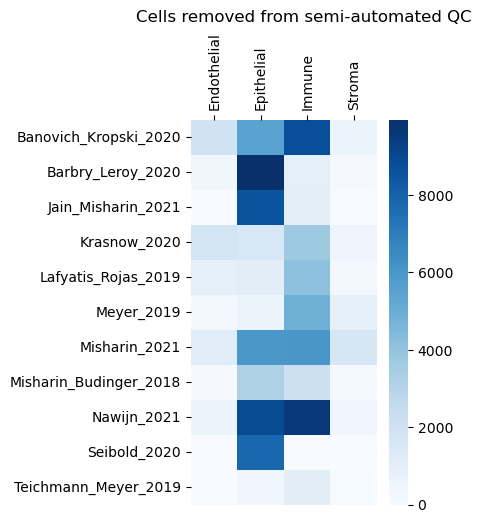

In [11]:
fig, ax = plt.subplots(figsize=figsize)
sns.heatmap(removed_df, cmap='Blues', ax=ax)
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=90)
fig.suptitle('Cells removed from semi-automated QC', y=1.1)
plt.show()

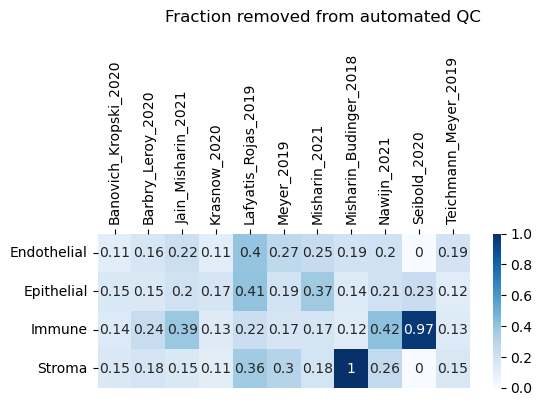

In [31]:
fig, ax = plt.subplots(figsize=(6, 2))
sns.heatmap(removed_frac_df.T, cmap='Blues', annot=True, ax=ax)
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=90)
fig.suptitle('Fraction removed from automated QC', y=2)
plt.show()

## Ridge plot

In [64]:
from pathlib import Path

In [66]:
file_pattern = f'{data_dir}/qc/dataset~{{dataset}}' #file_id~{{file_id}}/qc_metrics.parquet'

In [82]:
'file_id~split_data:doublets:Banovich_Kropski_2020--split_data_key=ann_level_1--split_data_value=Endothelial.zarr'

'file_id~split_data:doublets:Banovich_Kropski_2020--split_data_key=ann_level_1--split_data_value=Endothelial.zarr'

In [ ]:
qc_metrics_per_file = {
    '{study}-{lineage}'.format(): pd.read_anndata(file)
    for file in Path(file_pattern.format(dataset='QC')).iterdir()
    if file.suffix == '.zarr'
}

In [ ]:
qc_metric_df = pd.concat(
    {
        pd.read_parquet(file_pattern.format(file_id='Lee2020')),
        'organ sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasdk;jfkla': pd.read_parquet(file_pattern.format(file_id='organ')),
    }
).reset_index(level=0, names='file_id')

In [78]:
metric_df

,file_id,n_counts,log1p_n_counts,n_genes,log1p_n_genes,percent_mito,n_counts_mito,percent_ribo,n_counts_ribo,percent_hb,n_counts_hb,percent_top50,cell_passed_qc
AAACCCAAGAATGTTG-12-nCoV 6,Lee2020 sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasd...,5319.0,8.579228,1908,7.554335,3.102087,165.000000,23.237450,1235.999878,0.018801,1.0,35.025381,True
AAACCCAAGCATTGTC-19-Normal 4,Lee2020 sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasd...,7630.0,8.939974,2286,7.734996,7.863696,600.000000,29.790300,2272.999756,0.039318,3.0,38.912189,True
AAACCCAAGCTACGTT-6-Flu 3,Lee2020 sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasd...,5404.0,8.595079,1943,7.572503,9.529978,515.000000,19.189489,1037.000000,0.000000,0.0,37.971873,True
AAACCCAAGGCCGCTT-3-Flu 1,Lee2020 sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasd...,3980.0,8.289289,1582,7.367077,6.432161,256.000000,11.934673,475.000000,0.075377,3.0,34.522613,True
AAACCCAAGGCCTGCT-12-nCoV 6,Lee2020 sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasd...,3359.0,8.119697,1536,7.337588,6.490027,218.000000,12.801430,430.000031,0.029771,1.0,32.539446,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Schulte-Schrepping-9995-Schulte-Schrepping_C19-CB-0001_d7,organ sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasdk;...,4451.0,8.401109,1521,7.327781,3.662099,163.000015,35.946976,1599.999878,0.000000,0.0,34.554033,True
Schulte-Schrepping-9996-Schulte-Schrepping_C19-CB-0001_d7,organ sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasdk;...,12056.0,9.397401,3384,8.127109,2.372263,286.000000,10.359987,1249.000122,0.049768,6.0,27.480093,True
Schulte-Schrepping-9997-Schulte-Schrepping_C19-CB-0002_d8,organ sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasdk;...,8932.0,9.097507,2543,7.841493,3.392298,303.000031,20.734438,1852.000000,0.000000,0.0,30.116435,True
Schulte-Schrepping-9998-Schulte-Schrepping_C19-CB-0005_d15,organ sdfjaksdjf;kdsajfk;ajsdklfjaksdjfkjasdk;...,12749.0,9.453286,3460,8.149313,3.765001,480.000000,11.914660,1519.000000,0.000000,0.0,28.355165,True


In [57]:
def ridge_plot(df, group, metric, out_file=None, dpi=100):
    sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})
    
    def add_label(x, color, label, **kwargs):
        ax = plt.gca()
        ax.text(
            0,
            0.1,
            label,
            transform=ax.transAxes,
            fontsize=10,
            color=color,
            ha="right",
            va="center",
            clip_on=False,
        )


    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        
        grid = sns.FacetGrid(
            df,
            row=group,
            hue=group,
            aspect=15,
            height=0.65,
            palette=sns.cubehelix_palette(df[group].nunique(), rot=-.25, light=.7),
        )

        grid.map(sns.kdeplot, metric, fill=True, alpha=1, linewidth=1, bw_adjust=0.8, clip_on=False)
        grid.map(sns.kdeplot, metric, color='white', linewidth=1.5, bw_adjust=0.8, clip_on=False)
        grid.refline(y=0, linewidth=1.5, linestyle="-", color=None, clip_on=False)

        grid.map(add_label, metric)

        # Remove axes details that don't play well with overlap
        grid.set_titles('')
        grid.set(yticks=[], ylabel='')
        grid.despine(bottom=True, left=True)

        grid.set_xlabels(metric)

        grid.figure.subplots_adjust(hspace=-0.5)
        grid.figure.suptitle(f'QC metric ridge plot: {metric}', y=1.02)
    
    if out_file:
        grid.savefig(out_file, dpi=dpi, bbox_inches='tight')
        plt.close(grid.figure)

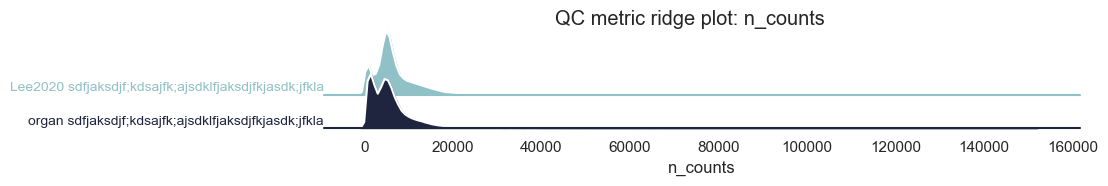

In [80]:
ridge_plot(metric_df, group='file_id', metric='n_counts') #, out_file='workspace/test.png')